In [ ]:
import pandas as pd
CLASS_NANES = ['World (1)', 'Sports (2)', 'Business (3)', 'Sci/Tech (4)']

¡¡¡ADVERTENCIA!!!


Ejecutar el Jupyter Notebook entero puede ser problemático de cara al consumo de RAM. No se recomienda tratar de ejecutar todo de golpe, es mejor ir por celdas. Las esenciales para que todo funciones son:
- Carga y procesado


Cada uno de los Subbloques de clasificadores funcionan de manera independiente, por lo que no es necesario ejecutar todo el bloque de Clasificadores si se desea comprobar alguno en concreto, pero sí es necesario cargar el conjunto de test en la primera celda de la sección.

## Carga y Preprocesado

In [1]:
from src.config import PATH_DATA # Ruta para buscar los datos. Por defecto, carpeta ../data/.
from src.preprocesado import cargar_datos

In [2]:
df_train = cargar_datos(test = False, guardar = True)
df_train.label.value_counts()

Cargando datos preprocesados...


label
2    29177
1    28906
3    28369
4    27912
Name: count, dtype: int64

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.preprocesado import nlp

Resumen estadístico del número de tokens:
count    114364.000000
mean         35.901236
std          11.714641
min           3.000000
25%          29.000000
50%          35.000000
75%          41.000000
max         199.000000
Name: num_tokens, dtype: float64


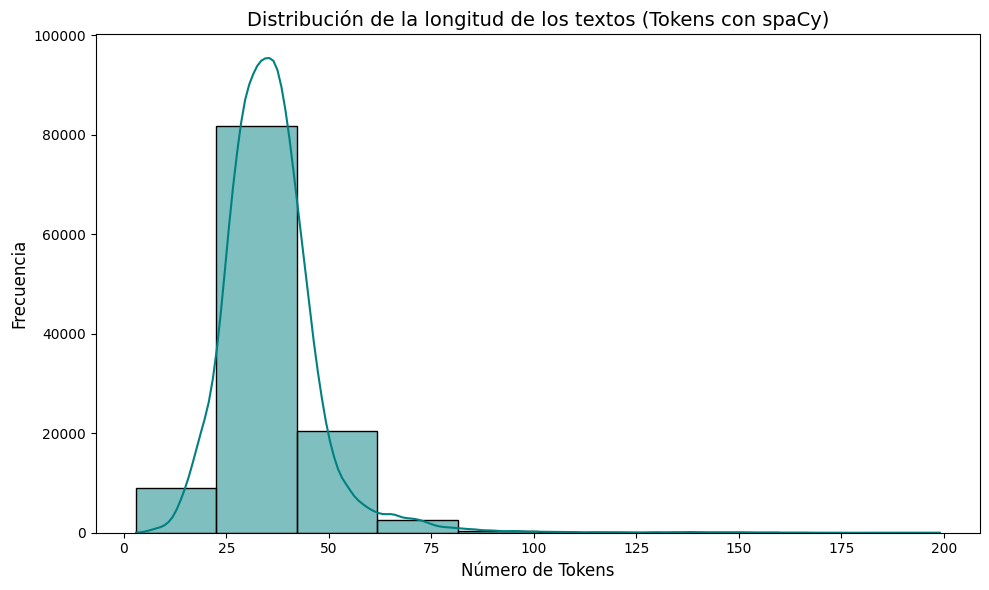

In [4]:
textos = df_train['desc_minimal'].astype(str).tolist()
df_train['num_tokens'] = [len(doc) for doc in nlp.pipe(textos)]

# 3. Visualizar la distribución
plt.figure(figsize=(10, 6))

sns.histplot(data=df_train, x='num_tokens', bins=10, kde=True, color='teal')

plt.title('Distribución de la longitud de los textos (Tokens con spaCy)', fontsize=14)
plt.xlabel('Número de Tokens', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

print("Resumen estadístico del número de tokens:")
print(df_train['num_tokens'].describe())

plt.tight_layout()
plt.show()

In [22]:
# Ejemplos de preprocesado
muestra = df_train.sample(1)

print("Preprocesado Mínimo:  ",muestra.desc_minimal.iloc[0])
print("Preprocesado Básico:  ",muestra.desc_basico.iloc[0])
print("Preprocesado Avanzado:",muestra.desc_avanzado.iloc[0])

Preprocesado Mínimo:   CBC SPORTS ONLINE - The Montreal Expos might be able to teach the Florida Marlins a thing or two about playing baseball at neutral venues.
Preprocesado Básico:   cbc sports online the montreal expos might be able to teach the florida marlins a thing or two about play baseball at neutral venue
Preprocesado Avanzado: cbc sports online montreal expos able teach florida marlins thing play baseball neutral venue


## Vectorizaciones

In [24]:
from src.config import PATH_MODELS # Ruta donde se guardan/leen los modelos.

### Dispersas

In [25]:
from src.vectorizacion import BoW, TF_IDF

In [26]:
df_bow, _ = BoW(df_train.desc_avanzado)
df_tfidf, _ = TF_IDF(df_train.desc_basico)

In [27]:
print("Palabras más comunes en BoW")
print(df_bow.sum(axis=0).sort_values(ascending=False)[:5])
print()
print("Palabras más representativas en TF-IDF")
print(df_tfidf.sum(axis=0).sort_values(ascending=False)[:5])

Palabras más comunes en BoW
say        22765
new        16502
year       12637
reuters    12114
company     8920
dtype: int64

Palabras más representativas en TF-IDF
39         3138.622974
say        2514.950094
new        1947.008368
year       1670.618949
reuters    1623.603382
dtype: float64


### Densas

In [28]:
from src.vectorizacion import get_word2vec_model
from src.vectorizacion import Word2Vec_Embeddings, BERT_Embeddings

In [29]:
w2v = get_word2vec_model()

Modelo word2vec-google-news-300 ya detectado en local. Cargando...


In [30]:
muestra = df_train.head(5)

print("Word2Vec")

df_w2v_muestra = Word2Vec_Embeddings(muestra['desc_basico'], w2v)

print(f"Forma de la matriz: {df_w2v_muestra.shape}") 
display(df_w2v_muestra.head(2)) 


print("BERT")
df_bert_muestra = BERT_Embeddings(muestra['desc_minimal'])

print(f"Forma de la matriz: {df_bert_muestra.shape}")
display(df_bert_muestra.head(2))

Word2Vec
Forma de la matriz: (5, 300)


,w2v_0,w2v_1,w2v_2,w2v_3,w2v_4,w2v_5,w2v_6,w2v_7,w2v_8,w2v_9,...,w2v_290,w2v_291,w2v_292,w2v_293,w2v_294,w2v_295,w2v_296,w2v_297,w2v_298,w2v_299
0,0.062481,0.047861,-0.048575,0.120399,-0.082773,-0.063986,0.017301,-0.131780,0.109371,0.103800,...,0.032903,0.042022,-0.108708,-0.003185,0.015118,-0.039438,-0.000207,-0.054226,0.034243,-0.015644
1,-0.007450,0.045787,0.012228,0.037999,-0.028809,-0.055073,-0.004690,-0.105679,0.101786,0.065398,...,-0.054319,0.024100,-0.059390,0.022803,-0.012943,-0.006139,-0.003521,-0.025143,0.003013,-0.021274


BERT
Cargando modelo BERT y tokenizador...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generando embeddings en CUDA...
Forma de la matriz: (5, 768)


,bert_hf_0,bert_hf_1,bert_hf_2,bert_hf_3,bert_hf_4,bert_hf_5,bert_hf_6,bert_hf_7,bert_hf_8,bert_hf_9,...,bert_hf_758,bert_hf_759,bert_hf_760,bert_hf_761,bert_hf_762,bert_hf_763,bert_hf_764,bert_hf_765,bert_hf_766,bert_hf_767
0,0.095519,0.299583,-0.185742,-0.271313,-0.514333,-0.408115,0.392311,0.445447,-0.423747,-0.371980,...,0.058801,0.07816,-0.153307,-0.143092,0.285756,0.460905,-0.077263,-0.473255,0.388358,0.254493
1,-0.518645,-0.330707,-0.303029,0.118394,-0.526549,-0.091507,0.053829,0.415719,-0.228031,-0.016307,...,0.003750,0.15563,0.565066,-0.197242,-0.170675,-0.177075,-0.199786,-0.345463,0.372727,0.184779


## Clasificadores

In [5]:
df_test = cargar_datos(test=True, guardar=True)
df_test.head(3)

Cargando datos preprocesados...


,label,title,desc_minimal,desc_basico,desc_avanzado
0,3,Fears for T N pension after talks,Unions representing workers at Turner Newall s...,union represent worker at turner newall say th...,union represent worker turner newall disappoin...
1,4,The Race is On: Second Private Team Sets Launc...,"SPACE.com - TORONTO, Canada -- A second team o...",space.com toronto canada a second team of rock...,toronto canada second team rocketeer compete m...
2,4,Ky. Company Wins Grant to Study Peptides (AP),AP - A company founded by a chemistry research...,ap a company found by a chemistry researcher a...,ap company found chemistry researcher universi...


### Clasificador con BoW + Naive Bayes

In [32]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

In [33]:
X_train_bow, vectorizador_bow = BoW(df_train['desc_avanzado'], max_features=3000)
X_test_bow,_ = BoW(df_test['desc_avanzado'], max_features=3000,vectorizador=vectorizador_bow)

y_train = df_train['label']
y_test = df_test['label']

In [34]:
print(f"- Dimensiones Train: {X_train_bow.shape}")
print(f"- Dimensiones Test:  {X_test_bow.shape}")

# Modelo de Naive Bayes
modelo_nb = MultinomialNB()
modelo_nb.fit(X_train_bow, y_train)

# Predicción
y_pred_bow = modelo_nb.predict(X_test_bow)

print("-"*30)
print("- Resultados de Naive Bayes")
print(f"- Accuracy Global: {accuracy_score(y_test, y_pred_bow):.4f}\n")
print("- Desglose por temática:")
print()
print(classification_report(y_test, y_pred_bow, target_names=CLASS_NANES))

- Dimensiones Train: (114364, 3000)
- Dimensiones Test:  (7569, 3000)
------------------------------
- Resultados de Naive Bayes
- Accuracy Global: 0.8709

- Desglose por temática:

              precision    recall  f1-score   support

   World (1)       0.88      0.88      0.88      1898
  Sports (2)       0.93      0.96      0.94      1891
Business (3)       0.84      0.82      0.83      1887
Sci/Tech (4)       0.84      0.83      0.83      1893

    accuracy                           0.87      7569
   macro avg       0.87      0.87      0.87      7569
weighted avg       0.87      0.87      0.87      7569



### Clasificación con TF-IDF + Regresor Logístico

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [36]:
X_train_tfidf, vectorizador_tfidf = TF_IDF(df_train['desc_basico'],max_features=3000)
X_test_tfidf,_ = TF_IDF(df_test['desc_basico'],max_features=3000, vectorizador=vectorizador_tfidf)

y_train = df_train['label']
y_test = df_test['label']

In [37]:
print(f"- Dimensiones Train: {X_train_tfidf.shape}")
print(f"- Dimensiones Test:  {X_test_tfidf.shape}")

# Modelo de Regresor Logístico
modelo_lr = LogisticRegression(max_iter=1000, random_state=123)
modelo_lr.fit(X_train_tfidf, y_train)

# Predicción
y_pred_tfidf = modelo_lr.predict(X_test_tfidf)

print("-"*30)
print("- Resultados de Regresor Logístico")
print(f"- Accuracy Global: {accuracy_score(y_test, y_pred_tfidf):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test, y_pred_tfidf, target_names=CLASS_NANES))

- Dimensiones Train: (114364, 3000)
- Dimensiones Test:  (7569, 3000)
------------------------------
- Resultados de Regresor Logístico
- Accuracy Global: 0.8899


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.90      0.88      0.89      1898
  Sports (2)       0.94      0.97      0.95      1891
Business (3)       0.86      0.85      0.85      1887
Sci/Tech (4)       0.86      0.86      0.86      1893

    accuracy                           0.89      7569
   macro avg       0.89      0.89      0.89      7569
weighted avg       0.89      0.89      0.89      7569



### Clasificación con Word2Vec + RandomForest

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from src.vectorizacion import get_word2vec_model, Word2Vec_Embeddings

In [9]:
w2v = get_word2vec_model()

Modelo word2vec-google-news-300 ya detectado en local. Cargando...


In [12]:
X_train_w2v = Word2Vec_Embeddings(df_train['desc_basico'], w2v)
X_test_w2v  = Word2Vec_Embeddings(df_test['desc_basico'], w2v)

y_train = df_train['label']
y_test = df_test['label']

In [14]:
print(f"- Dimensiones Train: {X_train_w2v.shape}")
print(f"- Dimensiones Test:  {X_test_w2v.shape}")

# Modelo de RandomForest
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=123, n_jobs=-1)
modelo_rf.fit(X_train_w2v, y_train)

# Predicción
y_pred_w2v = modelo_rf.predict(X_test_w2v)

print("-"*30)
print("- Resultados de RandomForest")
print(f"- Accuracy Global: {accuracy_score(y_test, y_pred_w2v):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test, y_pred_w2v, target_names=CLASS_NANES))

- Dimensiones Train: (114364, 300)
- Dimensiones Test:  (7569, 300)
------------------------------
- Resultados de RandomForest
- Accuracy Global: 0.8604


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.87      0.87      0.87      1898
  Sports (2)       0.92      0.95      0.93      1891
Business (3)       0.82      0.80      0.81      1887
Sci/Tech (4)       0.83      0.82      0.82      1893

    accuracy                           0.86      7569
   macro avg       0.86      0.86      0.86      7569
weighted avg       0.86      0.86      0.86      7569



### Clasificador con BERT + MLP

In [19]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
from src.vectorizacion import BERT_Embeddings

In [20]:
ruta_train_bert = PATH_DATA / "train_bert.parquet"
ruta_test_bert  = PATH_DATA / "test_bert.parquet"

y_train = df_train['label']
y_test = df_test['label']

if ruta_train_bert.exists() and ruta_test_bert.exists():
    print("Cargando Embeddings desde almacenamiento...")
    X_train_bert = pd.read_parquet(ruta_train_bert)
    X_test_bert  = pd.read_parquet(ruta_test_bert)
    
else:
    print("Creando Embeddings desde 0...")
    X_train_bert = BERT_Embeddings(df_train['desc_minimal'])
    X_test_bert  = BERT_Embeddings(df_test['desc_minimal'])
    
    # Guardar los embeddings en almacenamiento para evitar tener que cargarlos siempre
    X_train_bert.to_parquet(ruta_train_bert, engine="pyarrow", index=False)
    X_test_bert.to_parquet(ruta_test_bert, engine="pyarrow", index=False)


Creando Embeddings desde 0...
Cargando modelo BERT y tokenizador...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generando embeddings en CUDA...
Cargando modelo BERT y tokenizador...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generando embeddings en CUDA...


In [21]:
print(f"- Dimensiones Train: {X_train_bert.shape}")
print(f"- Dimensiones Test:  {X_test_bert.shape}")

modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(128,), 
    activation='relu', 
    solver='adam', 
    early_stopping=True, 
    max_iter=300, 
    random_state=123
)

modelo_mlp.fit(X_train_bert, y_train)

# Predicción
y_pred_bert = modelo_mlp.predict(X_test_bert)

print("-"*30)
print(f"- Accuracy Global: {accuracy_score(y_test, y_pred_bert):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test, y_pred_bert, target_names=CLASS_NANES))

- Dimensiones Train: (114364, 768)
- Dimensiones Test:  (7569, 768)
------------------------------
- Accuracy Global: 0.9160


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.95      0.92      0.93      1898
  Sports (2)       0.96      0.98      0.97      1891
Business (3)       0.90      0.86      0.88      1887
Sci/Tech (4)       0.86      0.91      0.88      1893

    accuracy                           0.92      7569
   macro avg       0.92      0.92      0.92      7569
weighted avg       0.92      0.92      0.92      7569



## Clasificador con modelo 'Fine-Tuneado'

Existe un script para hacer el fine-tuning que debe de ser ejecutado antes de llegar a esta sección del código.

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report
from datasets import Dataset
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    Trainer, 
    DataCollatorWithPadding
)

from src.config import FINE_TUNING_MODEL, FINE_TUNING_PATH

In [25]:
ruta_modelo = FINE_TUNING_PATH

if not ruta_modelo.exists() or not ruta_modelo.is_dir():
    raise FileNotFoundError(
        f"No se ha encontrado el modelo en '{ruta_modelo}'. "
        "Asegúrate de haber ejecutado el script 'fineTunning.py' y de que la ruta sea correcta."
    )

# Tokenizador y Modelo
print(f"- Cargando tokenizador de {FINE_TUNING_MODEL}...")
tokenizer = AutoTokenizer.from_pretrained(ruta_modelo)
modelo_ft = AutoModelForSequenceClassification.from_pretrained(ruta_modelo)

# Se copia para mantener los labels reales en test
df_eval = df_test.copy()
df_eval['label'] = df_eval['label'] - 1 
dataset_test = Dataset.from_pandas(df_eval[['desc_minimal', 'label']])

def tokenize_fn(examples):
    # Misma tokenización que en el script
    return tokenizer(examples["desc_minimal"], truncation=True, max_length=128)

print("- Tokenizando...")
tokenized_test = dataset_test.map(tokenize_fn, batched=True)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# 4. Instanciar Trainer solo para Inferencia (Sin TrainingArguments)
print("- Inferencia...")
trainer = Trainer(
    model=modelo_ft,
    processing_class=tokenizer,
    data_collator=data_collator
)

resultados = trainer.predict(tokenized_test)
y_pred = np.argmax(resultados.predictions, axis=1)

# Volver a hacer la conversión de las labels
y_pred_finetuning = y_pred + 1
y_test_real = df_test['label']


print("-"*30)
print("- Resultados del Fine-Tunning")
print(f"- Accuracy Global: {accuracy_score(y_test, y_pred_finetuning):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test_real, y_pred_finetuning, target_names=CLASS_NANES))

- Cargando tokenizador de distilbert-base-uncased...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

- Tokenizando...


Map:   0%|          | 0/7569 [00:00<?, ? examples/s]

- Inferencia...


------------------------------
- Resultados del Fine-Tunning
- Accuracy Global: 0.9341


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.94      0.95      0.95      1898
  Sports (2)       0.98      0.98      0.98      1891
Business (3)       0.90      0.91      0.90      1887
Sci/Tech (4)       0.91      0.89      0.90      1893

    accuracy                           0.93      7569
   macro avg       0.93      0.93      0.93      7569
weighted avg       0.93      0.93      0.93      7569



## Clasificador con LLM + Propmting

Esquema seguido para los 3 prompts: RTF (Role - Task - Format)

In [26]:
import re
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report

from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser

In [27]:
df_muestra = df_test.sample(n=100, random_state=123)[["label","desc_minimal"]].copy()

In [28]:
llm = ChatOllama(
    model="mixtral:8x7b",
    temperature=0.0
)

def predecir_categoria_langchain(texto_noticia):
    try:
        respuesta_cruda = cadena_clasificacion.invoke({"texto": texto_noticia})
        
        # Por si responde con algo más que el dígito
        match = re.search(r'[1-4]', respuesta_cruda)
        if match:
            return int(match.group(0))
        else:
            return -1

    except Exception as e:
        print(f"Error procesando el texto: {e}")
        return -1


### Zero-Shot

In [ ]:

template = """You are a highly accurate news classification system.
Your task is to classify the following news article into exactly ONE of these four categories:
1 - World
2 - Sports
3 - Business
4 - Sci/Tech

News Article: "{texto}"

Respond ONLY with the single digit (1, 2, 3, or 4). Do not include any explanations, words, or punctuation.
"""

prompt = PromptTemplate.from_template(template)

cadena_clasificacion = prompt | llm | StrOutputParser()


# Predicción
tqdm.pandas(desc="Pensando (Zero-Shot)...")
df_muestra['prediccion_llm'] = df_muestra['desc_minimal'].progress_apply(predecir_categoria_langchain)

# Evaluación
df_validos = df_muestra[df_muestra['prediccion_llm'] != -1]

y_test_llm = df_validos['label']
y_pred_llm = df_validos['prediccion_llm']


print("-"*30)
print(f"- Noticias evaluadas con éxito: {len(df_validos)}/{len(df_muestra)}")
print(f"- Accuracy de la Muestra: {accuracy_score(y_test_llm, y_pred_llm):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test_llm, y_pred_llm, target_names=CLASS_NANES, zero_division=0))

Pensando (Zero-Shot)...: 100%|██████████| 100/100 [03:21<00:00,  2.01s/it]

------------------------------
- Noticias evaluadas con éxito: 100/100
- Accuracy de la Muestra: 0.7500


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.56      0.91      0.69        22
  Sports (2)       0.90      0.86      0.88        22
Business (3)       0.84      0.64      0.72        33
Sci/Tech (4)       0.83      0.65      0.73        23

    accuracy                           0.75       100
   macro avg       0.78      0.77      0.76       100
weighted avg       0.79      0.75      0.75       100



### One-Shot

In [9]:
template_one_shot = """You are a highly accurate news classification system.
Your task is to classify news articles into exactly ONE of these four categories:
1 - World
2 - Sports
3 - Business
4 - Sci/Tech

Respond ONLY with the single digit. Do not include any explanations.

--- Example ---
News Article: "Wall Street surged on Thursday as tech stocks rallied, recovering from earlier losses this week."
Category: 3

--- Now classify this one ---
News Article: "{texto}"
Category: """

prompt = PromptTemplate.from_template(template_one_shot)

cadena_clasificacion = prompt | llm | StrOutputParser()

# Predicción
tqdm.pandas(desc="Pensando (One-Shot)...")
df_muestra['prediccion_llm'] = df_muestra['desc_minimal'].progress_apply(predecir_categoria_langchain)

# Evaluación
df_validos = df_muestra[df_muestra['prediccion_llm'] != -1]

y_test_llm = df_validos['label']
y_pred_llm = df_validos['prediccion_llm']

print("-"*30)
print(f"- Noticias evaluadas con éxito: {len(df_validos)}/{len(df_muestra)}")
print(f"- Accuracy de la Muestra: {accuracy_score(y_test_llm, y_pred_llm):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test_llm, y_pred_llm, target_names=CLASS_NANES, zero_division=0))

Pensando (One-Shot)...: 100%|██████████| 100/100 [01:50<00:00,  1.11s/it]

------------------------------
- Noticias evaluadas con éxito: 100/100
- Accuracy de la Muestra: 0.8000


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.65      0.91      0.75        22
  Sports (2)       0.85      1.00      0.92        22
Business (3)       0.88      0.64      0.74        33
Sci/Tech (4)       0.89      0.74      0.81        23

    accuracy                           0.80       100
   macro avg       0.82      0.82      0.80       100
weighted avg       0.82      0.80      0.80       100



### Few-Shot

In [10]:
template_few_shot = """You are a highly accurate news classification system.
Your task is to classify news articles into exactly ONE of these four categories:
1 - World
2 - Sports
3 - Business
4 - Sci/Tech

Respond ONLY with the single digit (1, 2, 3, or 4). Do not include any explanations.

--- Examples ---
News Article: "Peace talks in the Middle East stall after new border skirmishes."
Category: 1

News Article: "Real Madrid secures a stunning victory in the Champions League final with a last-minute goal."
Category: 2

News Article: "Oil prices surge to a six-month high following OPEC's decision to cut global production."
Category: 3

News Article: "Apple announces the new M4 chip, promising unprecedented speeds and AI capabilities for its laptops."
Category: 4

--- Now classify this one ---
News Article: "{texto}"
Category: """

prompt = PromptTemplate.from_template(template_few_shot)

cadena_clasificacion = prompt | llm | StrOutputParser()

# Predicción
tqdm.pandas(desc="Pensando (Few-Shot)...")
df_muestra['prediccion_llm'] = df_muestra['desc_minimal'].progress_apply(predecir_categoria_langchain)

# Evaluación
df_validos = df_muestra[df_muestra['prediccion_llm'] != -1]

y_test_llm = df_validos['label']
y_pred_llm = df_validos['prediccion_llm']

print("-"*30)
print(f"- Noticias evaluadas con éxito: {len(df_validos)}/{len(df_muestra)}")
print(f"- Accuracy de la Muestra: {accuracy_score(y_test_llm, y_pred_llm):.4f}\n")
print()
print("- Desglose por temática:")
print(classification_report(y_test_llm, y_pred_llm, target_names=CLASS_NANES, zero_division=0))

Pensando (Few-Shot)...: 100%|██████████| 100/100 [03:50<00:00,  2.30s/it]

------------------------------
- Noticias evaluadas con éxito: 100/100
- Accuracy de la Muestra: 0.8600


- Desglose por temática:
              precision    recall  f1-score   support

   World (1)       0.95      0.91      0.93        22
  Sports (2)       0.88      1.00      0.94        22
Business (3)       0.79      0.94      0.86        33
Sci/Tech (4)       0.87      0.57      0.68        23

    accuracy                           0.86       100
   macro avg       0.87      0.85      0.85       100
weighted avg       0.86      0.86      0.85       100

